# Hata lokalizasyonu kıyaslaması — "şurada hata var" (Parça 1)

Global Dice-kestirimi (`est_dice` ρ) *"bu maske iyi mi kötü mü?"* sorusunu yanıtlar. Ama bir
maskenin **nerede** yanlış olduğunu işaretlemek ayrı bir iştir ve global ρ bunu ölçmez. Bu defter,
hâlihazırda eğitilmiş modellerin ürettiği **voxel bazında hata haritalarını**, gerçek hata
haritasına (`bozuk XOR temiz`) karşı ölçer.

Ölçüt: **voxel-AUROC** ve **AP (PR-AUC)**. Hata voksülleri az (dengesiz sınıf) olduğundan AP daha
bilgilendiricidir. Hiçbir şey reconstruction sadakatine göre değil, yalnızca **enjekte edilen
hatayı ne kadar iyi yerelleştirdiğine** göre değerlendirilir. Eğitim yok; yalnızca yeni dosyalar.

Kıyaslanan üç işaretleyici (hepsi mevcut checkpoint'lerden):
- **recon_diff** — `|bozuk − reconstruct(bozuk)|` (yalnız şekil, görüntüsüz; VAR)
- **fpfn** — `max(FP, FN)` tahmin haritaları (görüntü-koşullu; G-VAR, G-VQ)
- **cascade** — `|refine(bozuk) − bozuk|` (Faz-4 referans-maske farkı)

Protokol: test bölünmesi, `seed=42`, `n_per_mask=5`, 3B primitifler.

In [1]:
import os
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')  # Windows OpenMP çifte-yükleme koruması

import sys, logging
from pathlib import Path
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.WARNING)

def find_root(start):
    p = Path(start).resolve()
    for c in [p, *p.parents]:
        if (c / 'scripts').is_dir() and (c / 'models').is_dir():
            return c
    return p

PROJECT_ROOT = find_root(Path.cwd())
for p in (PROJECT_ROOT, PROJECT_ROOT / 'scripts'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from data import load_config
from data.degradations import dice as _dice
from data.degradations_3d import PRIMITIVES_3D
from data.degradations_partial_3d import PARTIAL_PRIMITIVES_3D
from train import resolve_device, set_seed
import evaluate_correlation_3d as ev3d
import evaluate_correlation_imgcond as evic
import evaluate_correlation_imgcond_fpfn as evfpfn
import evaluate_localization as loc

# train/evaluate_* importları matplotlib'i Agg'e çeker; inline'ı importlardan SONRA kur.
%matplotlib inline

SEED = 42
device = resolve_device('auto')
CKPT = PROJECT_ROOT / 'outputs' / 'checkpoints'
ALL_FNS = {**PRIMITIVES_3D, **PARTIAL_PRIMITIVES_3D}
print('device =', device)

device = cuda


## Değerlendirme kümesi (görüntü + bozuk maske + temiz referans)

FP/FN ve cascade görüntü ister; recon_diff istemez. Tek bir küme kurulur (görüntü+maske),
her satırda temiz referans taşınır — gerçek hata haritası `bozuk XOR temiz`'den çıkar.

In [2]:
cfg = load_config(str(PROJECT_ROOT / 'configs' / 'vae3d_imgcond_fpfn.yaml'))
cfg.setdefault('data', {})['data_source'] = 'precomputed'
set_seed(SEED)
clean_masks, clean_images = evic.load_clean_image_volumes(cfg, 'test', None, SEED)
degrader = ev3d.calibrate_degrader(cfg, clean_masks, SEED)
broken, images, clean_ref, true_dice, is_clean = evfpfn.build_eval_set_fpfn(
    clean_masks, clean_images, degrader, 5, SEED)
is_clean = np.asarray(is_clean, dtype=bool)
print(f'hasta={len(clean_masks)}  hacim={len(broken)} '
      f'({is_clean.sum()} temiz + {(~is_clean).sum()} bozuk)  şekil={broken.shape[1:]}')

hasta=47  hacim=282 (47 temiz + 235 bozuk)  şekil=(64, 64, 64)


## İşaretleyicileri yükle ve voxel-AUROC / AP hesapla

`evaluate_localization` modülünün işaretleyici fonksiyonları ve skorlayıcısı yeniden kullanılır
(defterde tekrar tanım yok). Yalnızca diskte bulunan checkpoint'ler yüklenir.

In [3]:
REG = [
    ('recon_diff/VAR', loc.recon_diff_map, CKPT / 'vae3d_var_best.pt',    'recon'),
    ('fpfn/G-VAR',     loc.fpfn_map,       CKPT / 'vae3d_g_var_best.pt',  'fpfn_var'),
    ('fpfn/G-VQ',      loc.fpfn_map,       CKPT / 'vae3d_g_vq_best.pt',   'fpfn_vq'),
    ('cascade/Faz4',   loc.cascade_map,    CKPT / 'vae3d_h_cascade_best.pt', 'cascade'),
]
import evaluate_correlation_3d_var as evv
import evaluate_correlation_var_fpfn as evvf
import evaluate_correlation_cascade as evc

def _load(kind, path):
    if kind == 'recon':     return evv.load_model(path, device)
    if kind == 'fpfn_var':  return evvf.load_var_fpfn_model(path, device)
    if kind == 'fpfn_vq':   return evfpfn.load_fpfn_model(path, 'binary', 'vq', device)
    if kind == 'cascade':
        cfg_cas = load_config(str(PROJECT_ROOT / 'configs' / 'vae3d_cascade.yaml'))
        cfg_cas.setdefault('data', {})['data_source'] = 'precomputed'
        return evc.load_cascade(cfg_cas, path, device)

localizers = {}
rows = []
for lbl, fn, path, kind in REG:
    if not path.exists():
        print('YOK, atlanıyor:', lbl, path.name); continue
    model = _load(kind, path)
    localizers[lbl] = (fn, model)
    r = loc.score_localizer(fn, model, broken, images, clean_ref, true_dice, is_clean, device)
    row = {'işaretleyici': lbl, 'n': r['n'],
           'AUROC': round(r['auroc_mean'], 3), 'AUROC±': round(r['auroc_std'], 3),
           'AP': round(r['ap_mean'], 3), 'AP±': round(r['ap_std'], 3)}
    for b, bv in r['bands'].items():
        row[f'AUROC {b.split()[0]}'] = round(bv['auroc'], 3)
    rows.append(row)
    print(f"{lbl:18s} AUROC={r['auroc_mean']:.3f}  AP={r['ap_mean']:.3f}  (n={r['n']})")

df_loc = pd.DataFrame(rows).sort_values('AUROC', ascending=False).reset_index(drop=True)
display(df_loc)
print('Not: AUROC yüksek=iyi yerelleştirme; AP sınıf-dengesizliğine karşı daha katı. '
      'Bantlar gerçek-Dice seviyelerinde (kolay→çok zor) ayrıştırma gücünü gösterir.')

recon_diff/VAR     AUROC=0.846  AP=0.547  (n=235)
fpfn/G-VAR         AUROC=0.943  AP=0.627  (n=235)
fpfn/G-VQ          AUROC=0.924  AP=0.571  (n=235)
cascade/Faz4       AUROC=0.980  AP=0.835  (n=235)
Not: AUROC yüksek=iyi yerelleştirme; AP sınıf-dengesizliğine karşı daha katı. Bantlar gerçek-Dice seviyelerinde (kolay→çok zor) ayrıştırma gücünü gösterir.


,işaretleyici,n,AUROC,AUROC±,AP,AP±,AUROC kolay,AUROC orta,AUROC zor,AUROC cok
0,cascade/Faz4,235,0.980,0.015,0.835,0.169,0.971,0.978,0.984,0.986
1,fpfn/G-VAR,235,0.943,0.033,0.627,0.245,0.920,0.937,0.952,0.962
2,fpfn/G-VQ,235,0.924,0.043,0.571,0.248,0.894,0.917,0.939,0.949
3,recon_diff/VAR,235,0.846,0.096,0.547,0.200,0.932,0.872,0.801,0.775


## Hasta bazında overlay — hafif → ağır bozulma

Tek hastada üç bozulma seviyesinde her işaretleyicinin ürettiği yumuşak hata haritası, **gerçek
hata** (sarı = `bozuk XOR temiz`) ile yan yana gösterilir. Haritalar bozuk maske üzerine
bindirilir; kırmızı yoğunluk = "burada hata var" tahmini.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_lokalizasyon_panel.png


,seviye,bozulma,gerçek Dice,recon_diff/VAR,fpfn/G-VAR,fpfn/G-VQ,cascade/Faz4
0,hafif,erode/0.2,0.876,0.848,0.870,0.833,0.910
1,orta,center_only/0.5,0.570,0.652,0.934,0.918,0.947
2,ağır,center_only/0.75,0.095,0.579,0.965,0.960,0.966


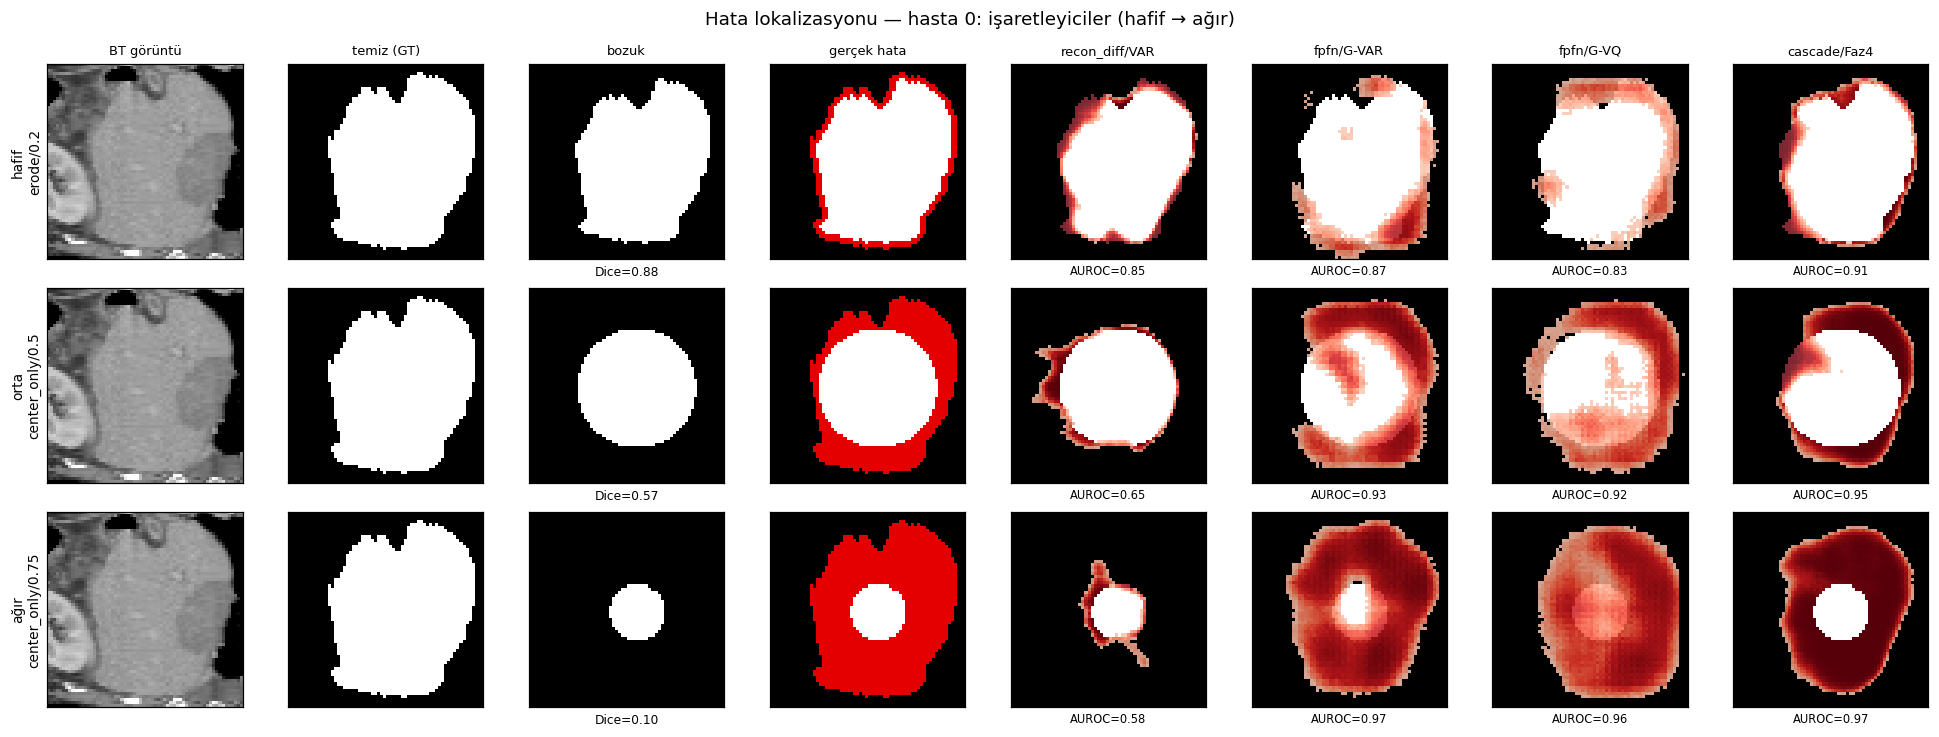

In [4]:
PANEL_IDX = 0
gt = clean_masks[PANEL_IDX].astype(bool); img = clean_images[PANEL_IDX]
specs = [('erode', 0.2, 'hafif'), ('center_only', 0.5, 'orta'), ('center_only', 0.75, 'ağır')]
zc = gt.shape[0] // 2
labels = list(localizers)
cols = ['BT görüntü', 'temiz (GT)', 'bozuk', 'gerçek hata'] + labels
fig, axes = plt.subplots(len(specs), len(cols), figsize=(2.25 * len(cols), 2.25 * len(specs)), squeeze=False)
prows = []
for ri, (name, sev, lvl) in enumerate(specs):
    b = np.asarray(ALL_FNS[name](gt, sev, np.random.default_rng(SEED))) > 0
    d_true = float(_dice(gt, b))
    true_err = b ^ gt
    axes[ri, 0].imshow(img[zc], cmap='gray'); axes[ri, 1].imshow(gt[zc], cmap='gray')
    axes[ri, 2].imshow(b[zc], cmap='gray')
    axes[ri, 3].imshow(b[zc], cmap='gray')
    axes[ri, 3].imshow(np.ma.masked_where(~true_err[zc], true_err[zc]), cmap='autumn_r', alpha=0.9, vmin=0, vmax=1)
    prow = {'seviye': lvl, 'bozulma': f'{name}/{sev}', 'gerçek Dice': round(d_true, 3)}
    for ci, lbl in enumerate(labels):
        fn, model = localizers[lbl]
        soft = fn(model, b[None].astype('float32'), img[None].astype('float32'), device)[0]
        from sklearn.metrics import roc_auc_score
        te = true_err.ravel()
        au = roc_auc_score(te, soft.ravel()) if te.any() and not te.all() else float('nan')
        prow[lbl] = round(float(au), 3)
        axes[ri, 4 + ci].imshow(b[zc], cmap='gray')
        axes[ri, 4 + ci].imshow(np.ma.masked_where(soft[zc] < 0.2, soft[zc]), cmap='Reds', alpha=0.85, vmin=0, vmax=1)
        axes[ri, 4 + ci].set_xlabel(f'AUROC={au:.2f}', fontsize=7.5)
    for ci in range(len(cols)):
        axes[ri, ci].set_xticks([]); axes[ri, ci].set_yticks([])
    axes[ri, 0].set_ylabel(f'{lvl}\n{name}/{sev}', fontsize=9)
    axes[ri, 2].set_xlabel(f'Dice={d_true:.2f}', fontsize=8)
    prows.append(prow)
for ci, t in enumerate(cols):
    axes[0, ci].set_title(t, fontsize=8.5)
fig.suptitle(f'Hata lokalizasyonu — hasta {PANEL_IDX}: işaretleyiciler (hafif → ağır)', fontsize=12)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'rapor_lokalizasyon_panel.png'
fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()
display(pd.DataFrame(prows))

## Bulguların özeti

Voxel-AUROC/AP tablosu, "nerede hata var" sorusuna hangi sinyalin en iyi cevap verdiğini gösterir.
Bu, global `est_dice` ρ ile **aynı şey değildir**: bir model global skoru güçlü verip
lokalizasyonu zayıf verebilir ya da tersi. Parça 2'de (diffusion denoising-artığı) bu tablodaki
en iyi değeri yenmeyi hedefliyoruz; karar yine bu lokalizasyon metriğiyle verilecek.

In [5]:
print('Lokalizasyon sıralaması (AUROC):')
for _, r in df_loc.iterrows():
    print(f"  {r['işaretleyici']:18s} AUROC={r['AUROC']:.3f}  AP={r['AP']:.3f}")

Lokalizasyon sıralaması (AUROC):
  cascade/Faz4       AUROC=0.980  AP=0.835
  fpfn/G-VAR         AUROC=0.943  AP=0.627
  fpfn/G-VQ          AUROC=0.924  AP=0.571
  recon_diff/VAR     AUROC=0.846  AP=0.547
